<a href="https://colab.research.google.com/github/ChetanyaGarg27/DA-projects/blob/main/Hospitality_revenue_optimization_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1 - Import libraries


In [1]:
import warnings
from pathlib import Path
import importlib.util
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, seaborn as sns
import plotly, plotly.express as px, plotly.graph_objects as go

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", 40, "display.max_colwidth", 150)
SEED = 42
versions = {m.__name__: m.__version__ for m in (np, pd, matplotlib, sns, plotly)}
versions["streamlit"] = "installed" if importlib.util.find_spec("streamlit") else "not installed here (installed in Step 9)"
print(versions)

{'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'plotly': '5.24.1', 'streamlit': 'not installed here (installed in Step 9)'}


## Step 2 - Load the hospitality dataset


In [3]:
def find():
    for n in ("hotel_bookings.csv", "hotel_bookings.csv.zip"):
        if Path(n).exists():
            return n
    try:
        from google.colab import files
        return next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError("Place hotel_bookings.csv (or the .zip) next to this notebook.")

raw = pd.read_csv(find())
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns  (>100K records; actual size disclosed)")
display(raw.head())
desc = {"hotel": "City Hotel or Resort Hotel", "is_canceled": "1 = cancelled or no-show", "lead_time": "days between booking and arrival",
        "arrival_date_year": "arrival year", "arrival_date_month": "arrival month name", "arrival_date_week_number": "ISO-style week of arrival",
        "arrival_date_day_of_month": "arrival day", "stays_in_weekend_nights": "Sat/Sun nights stayed", "stays_in_week_nights": "Mon-Fri nights stayed",
        "adults": "adult guests", "children": "child guests", "babies": "baby guests", "meal": "board type: SC/Undefined = none, BB, HB, FB",
        "country": "guest country (ISO)", "market_segment": "customer segment (Online TA, Direct, Groups, ...)", "distribution_channel": "booking channel (TA/TO, Direct, Corporate, GDS)",
        "is_repeated_guest": "1 = returning guest", "previous_cancellations": "guest's earlier cancellations", "previous_bookings_not_canceled": "guest's earlier completed bookings",
        "reserved_room_type": "room type booked (coded)", "assigned_room_type": "room type given", "booking_changes": "changes made to the booking",
        "deposit_type": "No Deposit / Non Refund / Refundable", "agent": "travel agent id", "company": "company id (94% missing)",
        "days_in_waiting_list": "days before confirmation", "customer_type": "Transient, Transient-Party, Contract, Group", "adr": "average daily rate (currency units per night)",
        "required_car_parking_spaces": "parking spaces requested", "total_of_special_requests": "number of special requests",
        "reservation_status": "Check-Out, Canceled or No-Show", "reservation_status_date": "date the status was set"}
print(f"\nColumns, types and meaning:")
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "description": pd.Series(desc)}))
print("Not in the data: booking ID, customer ID, room revenue, service revenue, rooms available/sold, costs.")

Saving hotel_bookings.csv.zip to hotel_bookings.csv.zip
119,390 rows × 32 columns  (>100K records; actual size disclosed)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03



Columns, types and meaning:


,dtype,description
hotel,object,City Hotel or Resort Hotel
is_canceled,int64,1 = cancelled or no-show
lead_time,int64,days between booking and arrival
arrival_date_year,int64,arrival year
arrival_date_month,object,arrival month name
arrival_date_week_number,int64,ISO-style week of arrival
arrival_date_day_of_month,int64,arrival day
stays_in_weekend_nights,int64,Sat/Sun nights stayed
stays_in_week_nights,int64,Mon-Fri nights stayed
adults,int64,adult guests


Not in the data: booking ID, customer ID, room revenue, service revenue, rooms available/sold, costs.


## Step 3 - Data cleaning and preparation


In [4]:
log = {}
df = raw.drop_duplicates()                                   # judged on ALL original columns
log["Exact duplicate rows removed"] = len(raw) - len(df)
miss = df.isna().sum()[lambda s: s > 0]
print("Missing values:", miss.to_dict())
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["has_agent"] = df["agent"].notna()
df = df.drop(columns=["agent", "company"])                   # id columns; 'company' is 94% missing
log["Missing cells handled (children→0, country→Unknown, agent→flag, company dropped)"] = int(miss.sum())

df["arrival"] = pd.to_datetime(df.arrival_date_year.astype(str) + "-" + df.arrival_date_month + "-" + df.arrival_date_day_of_month.astype(str), format="%Y-%B-%d")
df["status_date"] = pd.to_datetime(df.reservation_status_date)
for c in ["hotel", "market_segment", "distribution_channel", "customer_type", "deposit_type", "meal", "reserved_room_type", "assigned_room_type"]:
    df[c] = df[c].astype("string").str.strip()
df["nights"] = df.stays_in_weekend_nights + df.stays_in_week_nights
df["booking_date"] = df.arrival - pd.to_timedelta(df.lead_time, "D")
df["departure"] = df.arrival + pd.to_timedelta(df.nights, "D")
df["guests"] = df.adults + df.children + df.babies
df["arr_month"] = df.arrival.dt.to_period("M").dt.to_timestamp()
df["book_month"] = df.booking_date.dt.to_period("M").dt.to_timestamp()
df["moy"], df["dow"] = df.arrival.dt.month, df.arrival.dt.day_name()
df["status"] = df.reservation_status
df["days_before"] = (df.arrival - df.status_date).dt.days    # days between status date and arrival (cancellation notice)

rules = pd.concat({"ADR < 0": df.adr < 0, "ADR > 1000 (single extreme outlier)": df.adr > 1000, "0 nights": df.nights == 0,
                   "0 guests": df.guests == 0, "negative lead time": df.lead_time < 0, "unparseable date": df.arrival.isna()}, axis=1)
print("Invalid rows by rule:", rules.sum().to_dict())
n_invalid = int(rules.any(axis=1).sum())
log["Invalid rows removed (overlaps counted once)"] = n_invalid
df = df[~rules.any(axis=1)].reset_index(drop=True)

df["revenue"] = df.adr * df.nights                           # DERIVED room revenue
print("\nStatus vs is_canceled flag (cancellations, no-shows and completed stays are kept separate):")
print(pd.crosstab(df.status, df.is_canceled))
done = df[(df.status == "Check-Out") & (df.adr > 0)]         # realized, paid stays
log["Complimentary check-outs (ADR = 0): kept, excluded from ADR"] = int(((df.status == "Check-Out") & (df.adr == 0)).sum())
log["Cancellations"], log["No-shows"] = int((df.status == "Canceled").sum()), int((df.status == "No-Show").sum())
log["Realized paid stays (basis for revenue / ADR)"] = len(done)
log["Rows in cleaned dataset"] = len(df)
df.to_csv("clean_bookings.csv", index=False)

display(df.head())
display(pd.Series(log, name="rows").to_frame())
print(f"Arrival range: {df.arrival.min().date()} → {df.arrival.max().date()}")

Missing values: {'children': 4, 'country': 452, 'agent': 12193, 'company': 82137}
Invalid rows by rule: {'ADR < 0': 1, 'ADR > 1000 (single extreme outlier)': 1, '0 nights': 651, '0 guests': 166, 'negative lead time': 0, 'unparseable date': 0}

Status vs is_canceled flag (cancellations, no-shows and completed stays are kept separate):
is_canceled      0      1
status                   
Canceled         0  22985
Check-Out    62652      0
No-Show          0   1000


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_agent,arrival,status_date,nights,booking_date,departure,guests,arr_month,book_month,moy,dow,status,days_before,revenue
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,...,Transient,75.00,0,0,Check-Out,2015-07-02,False,2015-07-01,2015-07-02,1,2015-06-24,2015-07-02,1.00,2015-07-01,2015-06-01,7,Wednesday,Check-Out,-1,75.00
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,...,Transient,75.00,0,0,Check-Out,2015-07-02,True,2015-07-01,2015-07-02,1,2015-06-18,2015-07-02,1.00,2015-07-01,2015-06-01,7,Wednesday,Check-Out,-1,75.00
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,...,Transient,98.00,0,1,Check-Out,2015-07-03,True,2015-07-01,2015-07-03,2,2015-06-17,2015-07-03,2.00,2015-07-01,2015-06-01,7,Wednesday,Check-Out,-2,196.00
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,...,Transient,107.00,0,0,Check-Out,2015-07-03,False,2015-07-01,2015-07-03,2,2015-07-01,2015-07-03,2.00,2015-07-01,2015-07-01,7,Wednesday,Check-Out,-2,214.00
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,0.00,0,FB,PRT,Direct,Direct,0,0,0,C,...,Transient,103.00,0,1,Check-Out,2015-07-03,True,2015-07-01,2015-07-03,2,2015-06-22,2015-07-03,2.00,2015-07-01,2015-06-01,7,Wednesday,Check-Out,-2,206.00


,rows
Exact duplicate rows removed,31994
"Missing cells handled (children→0, country→Unknown, agent→flag, company dropped)",94786
Invalid rows removed (overlaps counted once),759
"Complimentary check-outs (ADR = 0): kept, excluded from ADR",906
Cancellations,22985
No-shows,1000
Realized paid stays (basis for revenue / ADR),61746
Rows in cleaned dataset,86637


Arrival range: 2015-07-01 → 2017-08-31


## Step 4 - Exploratory data analysis


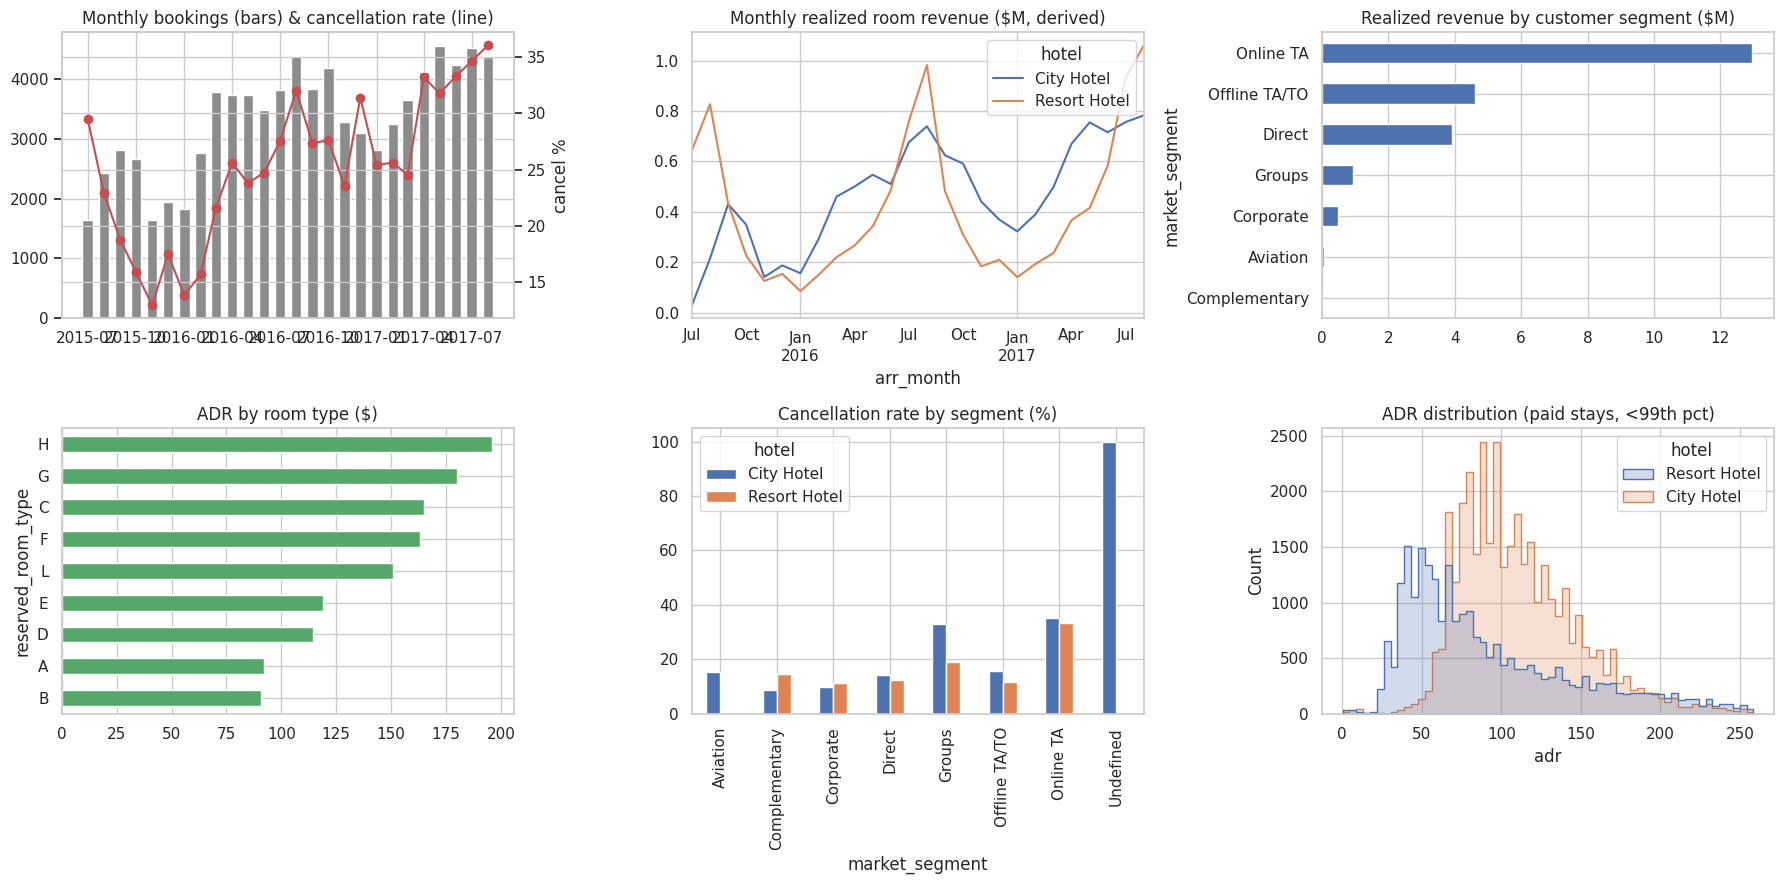

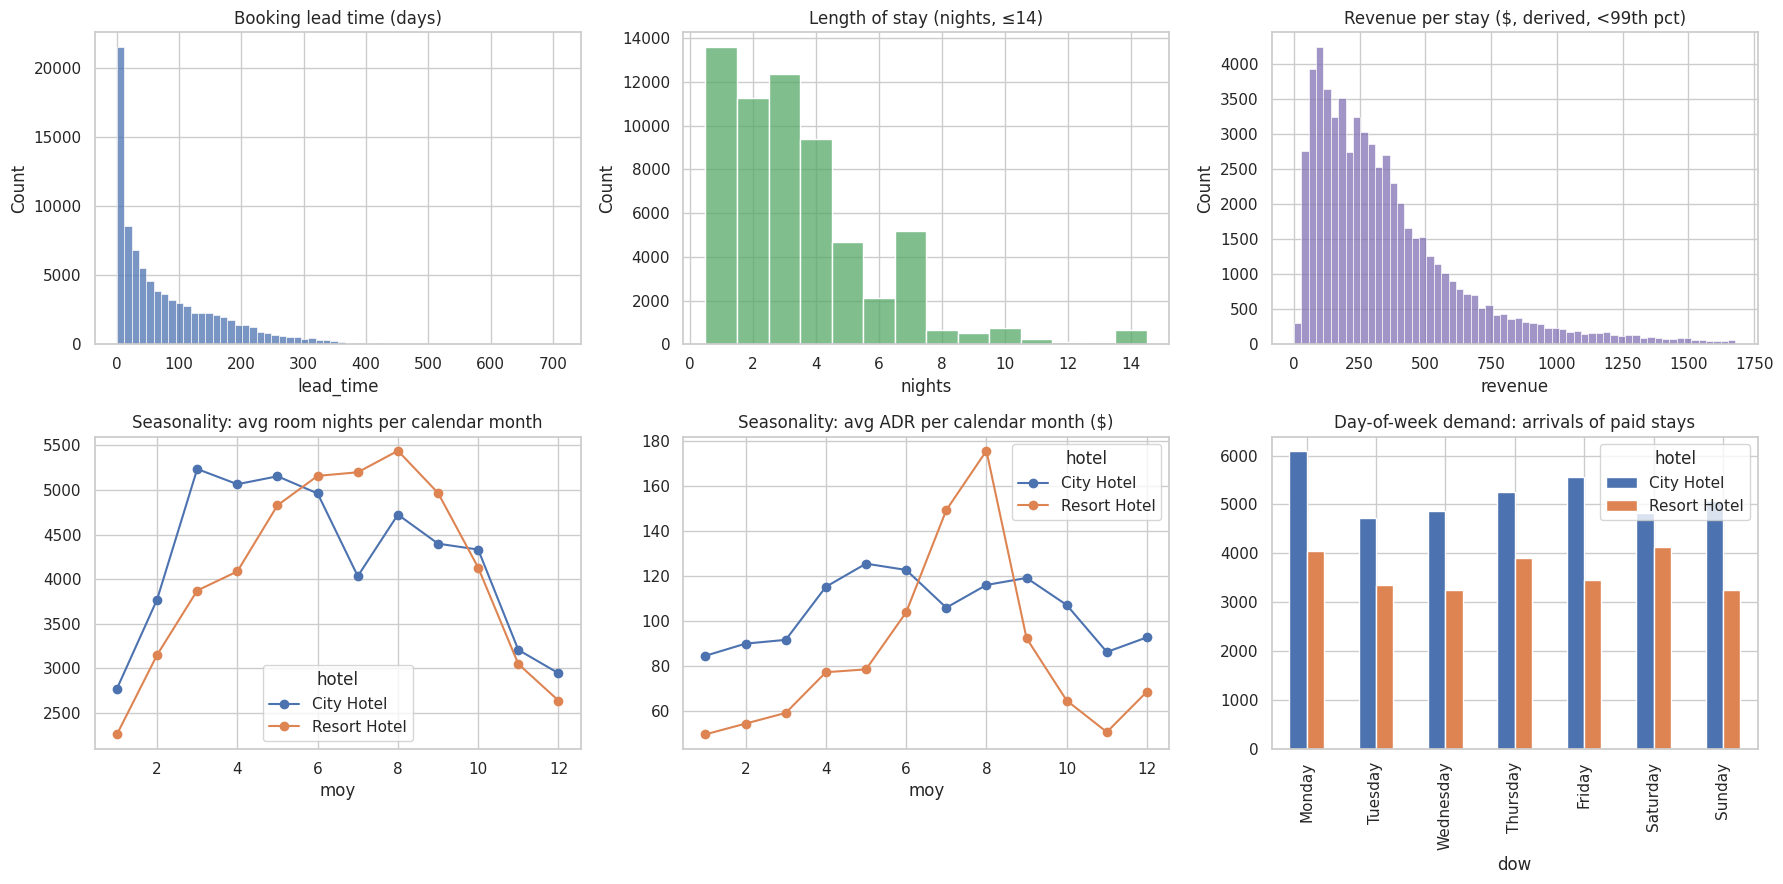

Observations (computed from the data):
  • Volume: 86,637 bookings; 26.5% cancelled and 1.2% no-show. City Hotel cancels 28.8% vs Resort 22.9%.
  • Revenue: highest realized monthly revenue in Aug 2017; Online TA contributes 56% of room revenue.
  • Price: median ADR $95; room types range from $91 (B) to $196 (H); 99th percentile ADR $259.
  • Stay & lead time: median stay 3 nights (14% stay ≥7 nights); median lead 50 days, 35% booked >90 days ahead.
  • City Hotel: busiest month Mar, quietest Jan; ADR peaks in May ($125) vs Jan ($84).
  • Resort Hotel: busiest month Aug, quietest Jan; ADR peaks in Aug ($176) vs Jan ($49).
  • Arrival weekday with most paid stays: Monday; fewest: Tuesday.
  • Services: meal-plan mix of paid stays {'BB': 79, 'HB': 11, 'SC': 10, 'Undefined': 1, 'FB': 0} (%). Service revenue is NOT in the data, so its share of total revenue cannot be measured. Occupancy patterns also cannot be shown (no inventory).


In [5]:
canc = df.assign(cancel=df.status.eq("Canceled"), noshow=df.status.eq("No-Show"))
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
m = canc.groupby("arr_month").agg(bookings=("hotel", "size"), cancel=("cancel", "mean"))
ax[0, 0].bar(m.index, m.bookings, width=20, color="#8C8C8C"); a2 = ax[0, 0].twinx(); a2.plot(m.index, m.cancel * 100, color="#C44E52", marker="o"); a2.set_ylabel("cancel %")
ax[0, 0].set_title("Monthly bookings (bars) & cancellation rate (line)")
done.groupby(["arr_month", "hotel"]).revenue.sum().unstack().div(1e6).plot(ax=ax[0, 1], title="Monthly realized room revenue ($M, derived)")
done.groupby("market_segment").revenue.sum().sort_values().div(1e6).plot.barh(ax=ax[0, 2], color="#4C72B0", title="Realized revenue by customer segment ($M)")
(done.groupby("reserved_room_type").revenue.sum() / done.groupby("reserved_room_type").nights.sum()).sort_values().plot.barh(ax=ax[1, 0], color="#55A868", title="ADR by room type ($)")
canc.groupby(["market_segment", "hotel"]).cancel.mean().mul(100).unstack().plot.bar(ax=ax[1, 1], title="Cancellation rate by segment (%)")
sns.histplot(done[done.adr < done.adr.quantile(.99)], x="adr", hue="hotel", bins=60, element="step", ax=ax[1, 2]); ax[1, 2].set_title("ADR distribution (paid stays, <99th pct)")
plt.tight_layout(); plt.show()

cell0 = done.groupby(["arr_month", "hotel"]).agg(rn=("nights", "sum"), rev=("revenue", "sum")).reset_index(); cell0["moy"] = cell0.arr_month.dt.month
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
sns.histplot(df.lead_time, bins=60, ax=ax[0, 0], color="#4C72B0"); ax[0, 0].set_title("Booking lead time (days)")
sns.histplot(done.nights[done.nights <= 14], discrete=True, ax=ax[0, 1], color="#55A868"); ax[0, 1].set_title("Length of stay (nights, ≤14)")
sns.histplot(done.revenue[done.revenue < done.revenue.quantile(.99)], bins=60, ax=ax[0, 2], color="#8172B3"); ax[0, 2].set_title("Revenue per stay ($, derived, <99th pct)")
cell0.groupby(["moy", "hotel"]).rn.mean().unstack().plot(ax=ax[1, 0], marker="o", title="Seasonality: avg room nights per calendar month")
cell0.assign(adr=cell0.rev / cell0.rn).groupby(["moy", "hotel"]).adr.mean().unstack().plot(ax=ax[1, 1], marker="o", title="Seasonality: avg ADR per calendar month ($)")
done.groupby(["dow", "hotel"]).size().unstack().reindex(order).plot.bar(ax=ax[1, 2], title="Day-of-week demand: arrivals of paid stays")
plt.tight_layout(); plt.show()

mo = lambda n: pd.Timestamp(2000, int(n), 1).strftime("%b")
seas = cell0.groupby(["moy", "hotel"]).rn.mean().unstack()
sa = cell0.assign(adr=cell0.rev / cell0.rn).groupby(["moy", "hotel"]).adr.mean().unstack()
rt = done.groupby("reserved_room_type").revenue.sum() / done.groupby("reserved_room_type").nights.sum()
print("Observations (computed from the data):")
print(f"  • Volume: {len(df):,} bookings; {canc.cancel.mean():.1%} cancelled and {canc.noshow.mean():.1%} no-show. City Hotel cancels {canc[canc.hotel == 'City Hotel'].cancel.mean():.1%} vs Resort {canc[canc.hotel == 'Resort Hotel'].cancel.mean():.1%}.")
print(f"  • Revenue: highest realized monthly revenue in {done.groupby('arr_month').revenue.sum().idxmax():%b %Y}; {done.groupby('market_segment').revenue.sum().idxmax()} contributes {done.groupby('market_segment').revenue.sum().max() / done.revenue.sum():.0%} of room revenue.")
print(f"  • Price: median ADR ${done.adr.median():,.0f}; room types range from ${rt.min():,.0f} ({rt.idxmin()}) to ${rt.max():,.0f} ({rt.idxmax()}); 99th percentile ADR ${done.adr.quantile(.99):,.0f}.")
print(f"  • Stay & lead time: median stay {done.nights.median():.0f} nights ({(done.nights >= 7).mean():.0%} stay ≥7 nights); median lead {df.lead_time.median():.0f} days, {(df.lead_time > 90).mean():.0%} booked >90 days ahead.")
for h in seas.columns:
    print(f"  • {h}: busiest month {mo(seas[h].idxmax())}, quietest {mo(seas[h].idxmin())}; ADR peaks in {mo(sa[h].idxmax())} (${sa[h].max():,.0f}) vs {mo(sa[h].idxmin())} (${sa[h].min():,.0f}).")
print(f"  • Arrival weekday with most paid stays: {done.dow.value_counts().idxmax()}; fewest: {done.dow.value_counts().idxmin()}.")
print(f"  • Services: meal-plan mix of paid stays {done.meal.value_counts(normalize=True).mul(100).round(0).astype(int).to_dict()} (%). Service revenue is NOT in the data, so its share of total revenue cannot be measured. Occupancy patterns also cannot be shown (no inventory).")

## Step 5 - Hospitality KPIs


In [6]:
%%writefile hotel_lib.py
import numpy as np, pandas as pd

TIERS = ["Low", "Mid", "High"]
ELAST = {"Price-insensitive (ε = -0.5)": -0.5, "Moderate (ε = -1.0)": -1.0, "Price-sensitive (ε = -1.5)": -1.5}
DEFAULTS = dict(high_up=0.05, low_down=0.10, uptake=0.15, bundle_price=15.0, bundle_cost=9.0)   # ILLUSTRATIVE assumptions
NO_BOARD = ("SC", "Undefined")                                                                   # stays without a meal plan = bundle-eligible


def realized(df):
    """Completed (checked-out) stays with a positive price."""
    return df[(df.status == "Check-Out") & (df.adr > 0)]


def kpis(f, by):
    """Room nights, revenue and ADR. ADR = revenue / room nights (NaN if no nights)."""
    g = f.groupby(by).agg(stays=("nights", "size"), room_nights=("nights", "sum"), revenue=("revenue", "sum"))
    g["ADR"] = g.revenue / g.room_nights.replace(0, np.nan)
    g["avg_los"] = g.room_nights / g.stays
    return g


def occupancy_table(done, inventory):
    """Occupancy and RevPAR per hotel-month. ONLY valid if `inventory` (rooms per hotel) is supplied."""
    m = kpis(done, ["hotel", "arr_month"]).reset_index()
    m = m[m.hotel.isin([h for h, v in inventory.items() if v])].copy()
    m["available_room_nights"] = m.hotel.map(inventory) * m.arr_month.dt.days_in_month
    m["occupancy_%"] = m.room_nights / m.available_room_nights * 100
    m["RevPAR"] = m.revenue / m.available_room_nights
    m["ADR_x_occupancy"] = m.ADR * m["occupancy_%"] / 100          # equals RevPAR: consistency check
    return m


def month_cells(done):
    c = done.groupby(["hotel", "arr_month"]).agg(rn=("nights", "sum"), rev=("revenue", "sum")).reset_index()
    c["ADR"] = c.rev / c.rn
    c["moy"] = c.arr_month.dt.month
    return c


def season_table(cells):
    """Per hotel & calendar month: avg room nights, ADR, demand index, Low/Mid/High demand tier, peak-demand-but-cheap flag."""
    s = cells.groupby(["hotel", "moy"]).agg(room_nights=("rn", "mean"), rev=("rev", "sum"), rn_sum=("rn", "sum"))
    s["ADR"] = s.rev / s.rn_sum
    s = s.drop(columns=["rev", "rn_sum"])
    g = s.groupby("hotel")
    s["demand_index"] = s.room_nights / g.room_nights.transform("mean") * 100

    def tier(x):
        if len(x) < 3:
            return pd.Series("Mid", index=x.index)
        return pd.qcut(x.rank(method="first"), 3, labels=TIERS).astype(str)

    s["tier"] = g.room_nights.transform(tier)
    s["ADR_vs_hotel_median"] = s.ADR / g.ADR.transform("median") - 1
    s["misaligned"] = (s.tier == "High") & (s.ADR_vs_hotel_median < 0)
    return s


def peak_gaps(cells, season):
    """High-demand hotel-months with ADR below the hotel's own median peak-month ADR (internal benchmark)."""
    hi = cells.merge(season.tier.rename("tier").reset_index(), on=["hotel", "moy"])
    hi = hi[hi.tier == "High"].copy()
    hi["target"] = hi.hotel.map(hi.groupby("hotel").ADR.median())
    hi["gap_rev"] = (hi.target - hi.ADR).clip(lower=0) * hi.rn
    return hi


def add_lead_bucket(df):
    df = df.copy()
    df["lead_bucket"] = pd.cut(df.lead_time, [-1, 7, 30, 90, 180, 365, 1000], labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"])
    return df


def segment_table(df, done):
    ov = done.revenue.sum() / done.nights.sum()
    s = kpis(done, "market_segment")
    s["ADR_index"] = s.ADR / ov * 100
    s["share_nights_%"] = s.room_nights / s.room_nights.sum() * 100
    s["share_revenue_%"] = s.revenue / s.revenue.sum() * 100
    s["cancel_noshow_%"] = df.assign(c=df.status.isin(["Canceled", "No-Show"])).groupby("market_segment").c.mean() * 100
    s["bookings"] = df.market_segment.value_counts()
    return s.sort_values("ADR_index")


def leakage_table(df, done, season, cells):
    """Issue / scope / metric / opportunity / status / action. Gross exposure and potential are never called 'confirmed loss'."""
    hi = peak_gaps(cells, season)
    lost = df[df.status.isin(["Canceled", "No-Show"])].assign(r=lambda t: t.adr * t.nights)
    late = lost[((lost.status == "No-Show") | (lost.days_before <= 7)) & (lost.deposit_type == "No Deposit")]
    hd = done.merge(season.tier.rename("tier").reset_index(), on=["hotel", "moy"]).query("tier == 'High'")
    lead = hd.groupby(hd.lead_time > 180).apply(lambda g: g.revenue.sum() / g.nights.sum()) if len(hd) else pd.Series(dtype=float)
    seg = segment_table(df, done)
    weak = seg[(seg["share_nights_%"] >= 1)].head(2)
    big = seg[seg.bookings >= 500]
    rows = []
    for h in sorted(done.hotel.unique()):
        x = hi[hi.hotel == h]
        if len(x):
            rows.append(("Under-priced peak months", h, f"{(x.gap_rev > 0).sum()} of {len(x)} peak hotel-months below the peak median ADR (${x.target.iloc[0]:,.0f}); avg gap ${(x.target - x.ADR).clip(lower=0).mean():,.0f}",
                         x.gap_rev.sum(), "Potential (assumes peak demand tolerates the median peak price)", "Raise rate floors / close low-rate fences in High-demand months"))
        l, a = late[late.hotel == h], lost[lost.hotel == h]
        if len(a):
            rows.append(("Late cancellations & no-shows (no deposit)", h, f"{len(l):,} bookings = {len(l) / len(a):.0%} of cancelled/no-show; gross exposure of ALL cancellations ${a.r.sum() / 1e6:,.1f}M",
                         l.r.sum(), "Potential upper bound (some rooms were resold)", "Deposit / non-refundable fences and tighter cancellation windows at short lead times"))
    if len(big):
        ws = big["cancel_noshow_%"].idxmax(); w = lost[lost.market_segment == ws]
        rows.append(("Highest cancellation segment", ws, f"{big.loc[ws, 'cancel_noshow_%']:.0f}% cancel+no-show; gross exposure ${w.r.sum() / 1e6:,.1f}M",
                     np.nan, "Gross exposure only, not a confirmed loss", "Stricter deposit terms for this segment; track resale of released rooms"))
    if len(weak):
        rows.append(("Low-ADR segments", ", ".join(weak.index), f"ADR index {', '.join(f'{v:.0f}' for v in weak.ADR_index)} (100 = overall); {weak['share_nights_%'].sum():.0f}% of room nights",
                     np.nan, "Not quantified: segments are priced differently by design", "Review contract rates; cap low-rate allocation in High-demand months"))
    if len(lead) == 2:
        rows.append(("Long-lead bookings in peak months", "High-demand months", f"ADR ${lead.get(True, np.nan):,.0f} when booked >180 days ahead vs ${lead.get(False, np.nan):,.0f} otherwise",
                     np.nan, "Association only; may reflect segment mix", "Test dynamic rate increases for advance bookings in peak periods"))
    up = done[done.assigned_room_type != done.reserved_room_type]
    rows += [("Room assigned ≠ room booked", "All", f"{len(up) / max(len(done), 1):.0%} of paid stays got a different room type (cannot tell paid upgrades from free ones)", np.nan,
              "Not quantified", "Audit upgrade policy; sell upgrades instead of giving them"),
             ("Low occupancy / unused inventory", "All", "Cannot be measured: no room inventory in the data", np.nan, "Not estimable", "Collect rooms available per night"),
             ("Missed ancillary / service revenue", "All", f"No service revenue recorded; {(done.total_of_special_requests > 0).mean():.0%} of stays made a special request (upsell signal only)",
              np.nan, "Not estimable", "Capture F&B / spa / parking revenue per booking")]
    return pd.DataFrame(rows, columns=["issue", "scope", "supporting_metric", "estimated_opportunity_$", "status", "proposed_action"])


def scenarios(done, season, **kw):
    """Assumption-based simulation (NOT a forecast). Constant-elasticity demand: volume × (1+price change)^ε.
    Room revenue and bundle contribution are kept separate so bundled services are never double-counted;
    only stays WITHOUT a meal plan are bundle-eligible. Room operating costs are unknown, so extra volume overstates profit."""
    p = {**DEFAULTS, **kw}
    d = done.merge(season.tier.rename("tier").reset_index(), on=["hotel", "moy"], how="left")
    d["tier"] = d.tier.fillna("Mid")
    g = d.groupby("tier").agg(rev=("revenue", "sum"), n=("nights", "sum"))
    elig = d[d.meal.isin(NO_BOARD)].groupby("tier").nights.sum()
    plans = {"Baseline (actual history)": ({}, False),
             "A. Demand-based pricing": ({"High": p["high_up"]}, False),
             "B. Occupancy improvement": ({"Low": -p["low_down"]}, False),
             "C. Room + service bundle": ({}, True),
             "D. Combined (A + B + C)": ({"High": p["high_up"], "Low": -p["low_down"]}, True)}
    rows = []
    for el, eps in ELAST.items():
        for name, (chg, bundle) in plans.items():
            rev = n = ben = 0.0
            for t in g.index:
                pc = chg.get(t, 0.0)
                vol = (1 + pc) ** eps
                rev += g.rev[t] * (1 + pc) * vol
                n += g.n[t] * vol
                ben += elig.get(t, 0.0) * vol
            b_rev = ben * p["uptake"] * p["bundle_price"] if bundle else 0.0
            b_con = ben * p["uptake"] * (p["bundle_price"] - p["bundle_cost"]) if bundle else 0.0
            rows.append(dict(elasticity=el, scenario=name, room_nights=n, ADR=rev / n, room_revenue=rev, bundle_revenue=b_rev,
                             bundle_contribution=b_con, total_value=rev + b_con))
    s = pd.DataFrame(rows)
    b = s[s.scenario.str.startswith("Baseline")].iloc[0]
    s["ADR_chg_%"] = (s.ADR / b.ADR - 1) * 100
    s["occupancy_chg_%"] = (s.room_nights / b.room_nights - 1) * 100       # relative change; inventory assumed constant
    s["RevPAR_chg_%"] = (s.room_revenue / b.room_revenue - 1) * 100        # = room-revenue change when inventory is constant
    s["room_revenue_chg_$"] = s.room_revenue - b.room_revenue
    s["total_value_chg_$"] = s.total_value - b.total_value
    s["total_value_chg_%"] = (s.total_value / b.total_value - 1) * 100
    return s

Writing hotel_lib.py


Overall:


,stays,room_nights,revenue,ADR,avg_los
all,,,,,
All,61746,218166,"22,967,611.95",105.28,3.53



By hotel:


,stays,room_nights,revenue,ADR,avg_los
hotel,,,,,
City Hotel,36382,109963,"12,150,577.73",110.50,3.02
Resort Hotel,25364,108203,"10,817,034.22",99.97,4.27



By room type:


...


By customer segment:


,stays,room_nights,revenue,ADR,avg_los
market_segment,,,,,
Aviation,178,672,"68,968.36",102.63,3.78
Complementary,57,143,"4,804.53",33.60,2.51
Corporate,3631,7119,"483,728.83",67.95,1.96
Direct,9861,30900,"3,925,328.52",127.03,3.13
Groups,3405,12172,"922,900.97",75.82,3.57
Offline TA/TO,11595,55816,"4,595,456.13",82.33,4.81
Online TA,33019,111344,"12,966,424.61",116.45,3.37



By booking channel:


,stays,room_nights,revenue,ADR,avg_los
distribution_channel,,,,,
Corporate,4276,9715,"686,852.81",70.70,2.27
Direct,10387,32854,"4,038,679.62",122.93,3.16
GDS,141,245,"30,779.36",125.63,1.74
TA/TO,46941,175347,"18,210,736.66",103.86,3.74
Undefined,1,5,563.50,112.70,5.00



Occupancy and RevPAR NOT calculated: no room inventory in the data. Required: rooms per hotel (net of out-of-order rooms) → available room-nights = rooms × days in period.


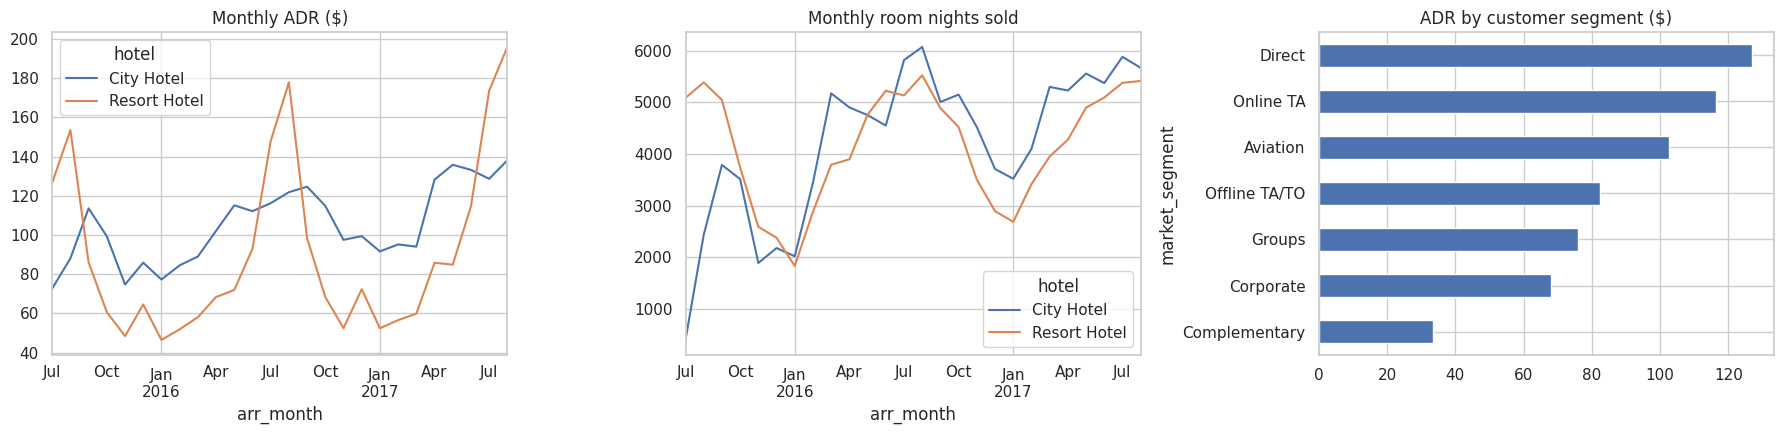

In [8]:
import importlib, hotel_lib as hl
importlib.reload(hl)

overall = hl.kpis(done.assign(all="All"), "all")
by_hotel, by_room, by_seg = hl.kpis(done, "hotel"), hl.kpis(done, "reserved_room_type"), hl.kpis(done, "market_segment")
by_chan = hl.kpis(done, "distribution_channel")
monthly = hl.kpis(done, ["hotel", "arr_month"]).reset_index()
print("Overall:"); display(overall)
for name, t in [("hotel", by_hotel), ("room type", by_room), ("customer segment", by_seg), ("booking channel", by_chan)]:
    print(f"\nBy {name}:"); display(t)

INVENTORY = {}   # e.g. {"City Hotel": 300, "Resort Hotel": 200}  → rooms available. NOT in the dataset; leave empty unless you know it.
if INVENTORY:
    occ = hl.occupancy_table(done, INVENTORY)
    print("\nOccupancy & RevPAR from YOUR inventory figures (check occupancy ≤ 100%):"); display(occ.tail())
else:
    print("\nOccupancy and RevPAR NOT calculated: no room inventory in the data. Required: rooms per hotel (net of out-of-order rooms) → available room-nights = rooms × days in period.")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
monthly.pivot(index="arr_month", columns="hotel", values="ADR").plot(ax=ax[0], title="Monthly ADR ($)")
monthly.pivot(index="arr_month", columns="hotel", values="room_nights").plot(ax=ax[1], title="Monthly room nights sold")
by_seg.ADR.sort_values().plot.barh(ax=ax[2], color="#4C72B0", title="ADR by customer segment ($)")
plt.tight_layout(); plt.show()

## Step 6 - Demand analysis and benchmarking


City Hotel: peak months ['Mar', 'May', 'Apr'] | low months ['Jan', 'Dec', 'Nov'] | peak-demand months priced below the hotel's median ADR: ['Mar']
Resort Hotel: peak months ['Aug', 'Jul', 'Jun'] | low months ['Jan', 'Dec', 'Nov'] | peak-demand months priced below the hotel's median ADR: none


room_nights    ADR  demand_index  tier  ADR_vs_hotel_median  \
hotel        moy                                                                
City Hotel   1       2,772.50  86.38         65.75   Low                -0.23   
             2       3,772.00  90.32         89.45   Low                -0.19   
             3       5,235.50  91.57        124.16  High                -0.18   
             4       5,065.00 115.60        120.11  High                 0.03   
             5       5,154.00 126.30        122.22  High                 0.13   
             6       4,961.50 123.56        117.66  High                 0.10   
             7       4,033.67 120.82         95.66   Mid                 0.08   
             8       4,724.33 122.53        112.03   Mid                 0.09   
             9       4,398.50 119.89        104.31   Mid                 0.07   
             10      4,332.00 108.54        102.73   Mid                -0.03   
             11      3,207.50  90.80         76.06   Low                -0.19   
             12      2,946.00  94.42         69.86   Low                -0.16   
Resort Hotel 1       2,260.50  49.99         55.61   Low                -0.32   
             2       3,150.50  54.41         77.50   Low                -0.26   
             3       3,873.00  58.99         95.27   Mid                -0.19   
             4       4,087.00  77.51        100.54   Mid                 0.06   
             5       4,828.50  78.48        118.78   Mid                 0.07   
             6       5,158.50 103.67        126.89  High                 0.42   
             7       5,198.67 149.81        127.88  High                 1.05   
             8       5,440.00 175.86        133.82  High                 1.40   
             9       4,967.00  92.13        122.18  High                 0.26   
             10      4,130.50  64.85        101.61   Mid                -0.11   
             11      3,049.00  50.74         75.00   Low                -0.31   
             12      2,639.00  68.85         64.92   Low                -0.06   

                  misaligned  
hotel        moy              
City Hotel   1         False  
             2         False  
             3          True  
             4         False  
             5         False  
             6         False  
             7         False  
             8         False  
             9         False  
             10        False  
             11        False  
             12        False  
Resort Hotel 1         False  
             2         False  
             3         False  
             4         False  
             5         False  
             6         False  
             7         False  
             8         False  
             9         False  
             10        False  
             11        False  
             12        False

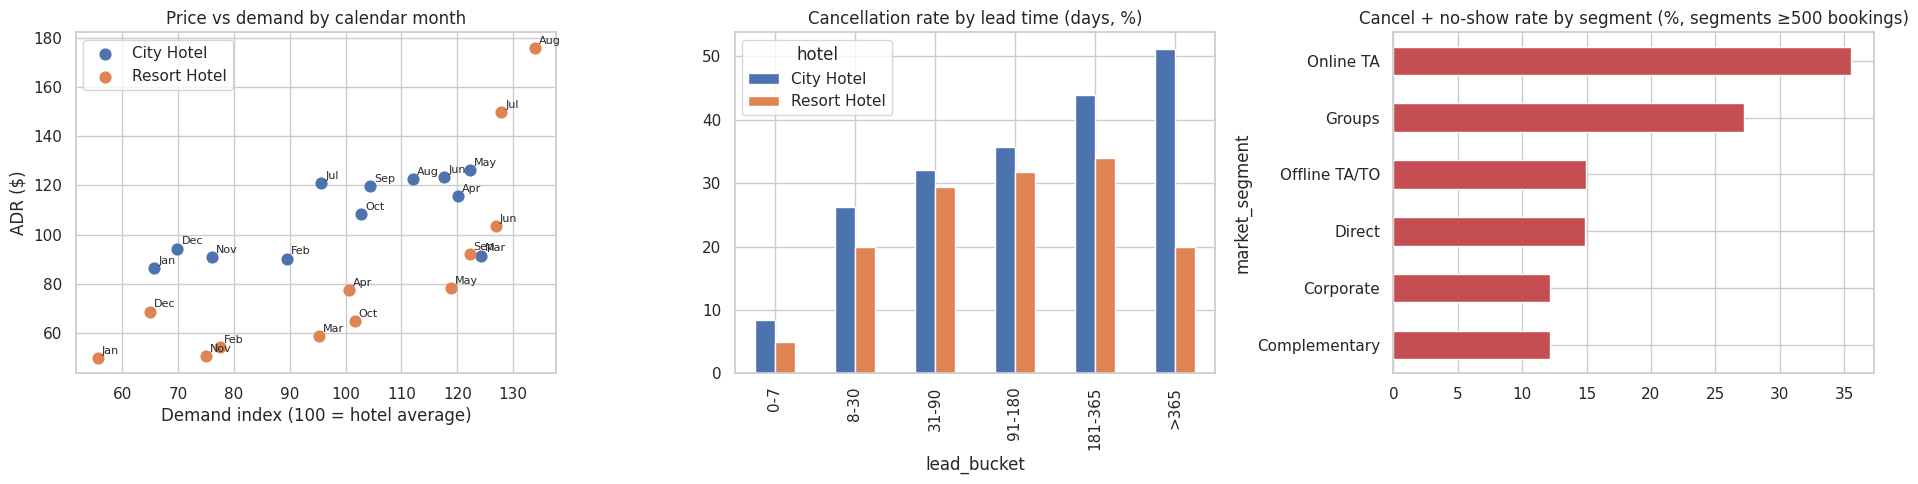

Internal baseline - Jan-Aug 2017 vs Jan-Aug 2016 (% change):


,room_nights %chg,revenue %chg,ADR %chg
hotel,,,
City Hotel,10.58,26.00,13.95
Resort Hotel,6.25,19.46,12.43


Segments, weakest ADR first (ADR index: 100 = overall):


,bookings,room_nights,ADR,ADR_index,share_nights_%,share_revenue_%,cancel_noshow_%
market_segment,,,,,,,
Complementary,682,143,33.60,31.91,0.07,0.02,12.17
Corporate,4155,7119,67.95,64.54,3.26,2.11,12.20
Groups,4891,12172,75.82,72.02,5.58,4.02,27.21
Offline TA/TO,13748,55816,82.33,78.21,25.58,20.01,14.95
Aviation,222,672,102.63,97.49,0.31,0.30,19.82
Online TA,51285,111344,116.45,110.62,51.04,56.46,35.55
Direct,11652,30900,127.03,120.67,14.16,17.09,14.87


Room types:


,stays,room_nights,ADR,ADR_index
reserved_room_type,,,,
B,652,2135,90.74,86.19
A,40715,130275,91.95,87.34
D,11981,49702,114.41,108.67
E,4300,20350,118.85,112.90
L,4,5,150.80,143.24
F,1907,6915,163.26,155.07
C,602,2684,165.06,156.79
G,1238,4899,180.06,171.04
H,347,1201,196.10,186.28


In [9]:
cells = hl.month_cells(done)
season = hl.season_table(cells)
for h, t in season.groupby(level=0):
    print(f"{h}: peak months {[mo(i) for i in t.nlargest(3, 'room_nights').index.get_level_values(1)]} | low months {[mo(i) for i in t.nsmallest(3, 'room_nights').index.get_level_values(1)]} "
          f"| peak-demand months priced below the hotel's median ADR: {[mo(i) for i in t[t.misaligned].index.get_level_values(1)] or 'none'}")
display(season.round(2))

df = hl.add_lead_bucket(df)
cancel_by_lead = df.assign(c=df.status.eq("Canceled")).pivot_table(index="lead_bucket", columns="hotel", values="c", aggfunc="mean").mul(100)
seg = hl.segment_table(df, done)
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for h, t in season.groupby(level=0):
    ax[0].scatter(t.demand_index, t.ADR, label=h, s=60)
    for (_, m_), r in t.iterrows(): ax[0].annotate(mo(m_), (r.demand_index, r.ADR), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[0].set(xlabel="Demand index (100 = hotel average)", ylabel="ADR ($)", title="Price vs demand by calendar month"); ax[0].legend()
cancel_by_lead.plot.bar(ax=ax[1], title="Cancellation rate by lead time (days, %)")
seg[seg.bookings >= 500]["cancel_noshow_%"].sort_values().plot.barh(ax=ax[2], color="#C44E52", title="Cancel + no-show rate by segment (%, segments ≥500 bookings)")
plt.tight_layout(); plt.show()

hist = hl.kpis(done[(done.moy <= 8) & done.arrival_date_year.isin([2016, 2017])], ["hotel", "arrival_date_year"])[["room_nights", "revenue", "ADR"]].unstack()
print("Internal baseline - Jan-Aug 2017 vs Jan-Aug 2016 (% change):")
display(pd.concat({k: (hist[k][2017] / hist[k][2016] - 1) * 100 for k in ["room_nights", "revenue", "ADR"]}, axis=1).rename(columns=lambda c: c + " %chg"))
print("Segments, weakest ADR first (ADR index: 100 = overall):")
display(seg[["bookings", "room_nights", "ADR", "ADR_index", "share_nights_%", "share_revenue_%", "cancel_noshow_%"]])
rtk = hl.kpis(done, "reserved_room_type"); rtk["ADR_index"] = rtk.ADR / overall.ADR.iloc[0] * 100
print("Room types:"); display(rtk.sort_values("ADR_index")[["stays", "room_nights", "ADR", "ADR_index"]])

## Step 7 - Revenue leakage analysis


,issue,scope,supporting_metric,estimated_opportunity_$,status,proposed_action
0,Under-priced peak months,City Hotel,4 of 8 peak hotel-months below the peak median ADR ($114); avg gap $7,"294,678.96",Potential (assumes peak demand tolerates the median peak price),Raise rate floors / close low-rate fences in High-demand months
1,Late cancellations & no-shows (no deposit),City Hotel,"3,435 bookings = 21% of cancelled/no-show; gross exposure of ALL cancellations $6.6M","1,244,659.99",Potential upper bound (some rooms were resold),Deposit / non-refundable fences and tighter cancellation windows at short lead times
2,Under-priced peak months,Resort Hotel,5 of 10 peak hotel-months below the peak median ADR ($137); avg gap $17,"848,411.72",Potential (assumes peak demand tolerates the median peak price),Raise rate floors / close low-rate fences in High-demand months
3,Late cancellations & no-shows (no deposit),Resort Hotel,"1,203 bookings = 15% of cancelled/no-show; gross exposure of ALL cancellations $4.9M","379,207.67",Potential upper bound (some rooms were resold),Deposit / non-refundable fences and tighter cancellation windows at short lead times
4,Highest cancellation segment,Online TA,36% cancel+no-show; gross exposure $9.3M,NaN,"Gross exposure only, not a confirmed loss",Stricter deposit terms for this segment; track resale of released rooms
5,Low-ADR segments,"Corporate, Groups","ADR index 65, 72 (100 = overall); 9% of room nights",NaN,Not quantified: segments are priced differently by design,Review contract rates; cap low-rate allocation in High-demand months
6,Long-lead bookings in peak months,High-demand months,ADR $111 when booked >180 days ahead vs $132 otherwise,NaN,Association only; may reflect segment mix,Test dynamic rate increases for advance bookings in peak periods
7,Room assigned ≠ room booked,All,19% of paid stays got a different room type (cannot tell paid upgrades from free ones),NaN,Not quantified,Audit upgrade policy; sell upgrades instead of giving them
8,Low occupancy / unused inventory,All,Cannot be measured: no room inventory in the data,NaN,Not estimable,Collect rooms available per night
9,Missed ancillary / service revenue,All,No service revenue recorded; 54% of stays made a special request (upsell signal only),NaN,Not estimable,Capture F&B / spa / parking revenue per booking


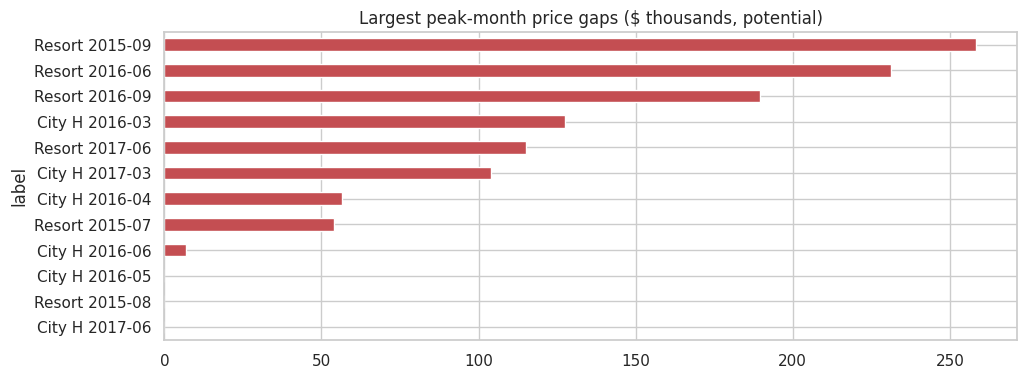

Quantified potential: $2.8M (pricing and cancellation estimates overlap in principle; do not add them). Realized room revenue in the data: $23.0M.


In [10]:
leak = hl.leakage_table(df, done, season, cells)
display(leak)
pk = hl.peak_gaps(cells, season)
fig, ax = plt.subplots(figsize=(11, 4))
pk.assign(label=pk.hotel.str[:6] + " " + pk.arr_month.dt.strftime("%Y-%m")).sort_values("gap_rev", ascending=False).head(12).set_index("label").gap_rev.div(1e3).plot.barh(ax=ax, color="#C44E52")
ax.invert_yaxis(); ax.set_title("Largest peak-month price gaps ($ thousands, potential)")
plt.show()
print(f"Quantified potential: ${leak['estimated_opportunity_$'].sum() / 1e6:,.1f}M (pricing and cancellation estimates overlap in principle; do not add them). "
      f"Realized room revenue in the data: ${done.revenue.sum() / 1e6:,.1f}M.")

## Step 8 - Pricing and bundling scenarios


Scenario comparison (moderate demand sensitivity, ε = -1.0):


,room_nights,ADR,room_revenue,bundle_contribution,total_value,ADR_chg_%,occupancy_chg_%,RevPAR_chg_%,total_value_chg_$,total_value_chg_%
scenario,,,,,,,,,,
Baseline (actual history),"218,166.00",105.28,"22,967,611.95",0.00,"22,967,611.95",0.00,0.00,0.00,0.00,0.00
A. Demand-based pricing,"213,737.48",107.46,"22,967,611.95",0.00,"22,967,611.95",2.07,-2.03,0.00,0.00,0.00
B. Occupancy improvement,"223,454.22",102.78,"22,967,611.95",0.00,"22,967,611.95",-2.37,2.42,0.00,0.00,0.00
C. Room + service bundle,"218,166.00",105.28,"22,967,611.95","16,105.50","22,983,717.45",0.00,0.00,0.00,"16,105.50",0.07
D. Combined (A + B + C),"219,025.70",104.86,"22,967,611.95","16,277.89","22,983,889.84",-0.39,0.39,0.00,"16,277.89",0.07


Range of total-value change (%) across assumed sensitivities:


elasticity,Moderate (ε = -1.0),Price-insensitive (ε = -0.5),Price-sensitive (ε = -1.5)
scenario,,,
A. Demand-based pricing,0.00,1.27,-1.24
B. Occupancy improvement,0.00,-0.79,0.83
C. Room + service bundle,0.07,0.07,0.07
D. Combined (A + B + C),0.07,0.55,-0.34


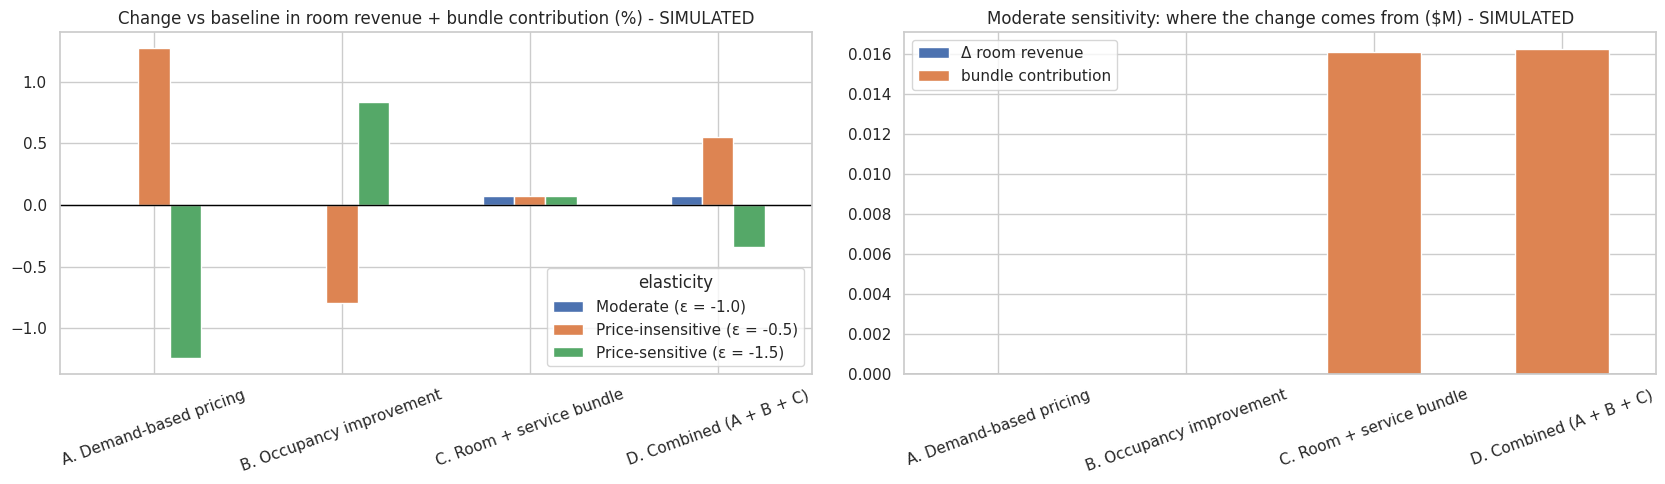

Break-even logic: a price rise raises room revenue only while elasticity > -1/(1+p) → +3%: -0.97, +5%: -0.95, +10%: -0.91; a discount of d% needs +5.3% (d=5%), 11.1% (d=10%), 17.6% (d=15%) room nights to break even.
Advantages / limits / risks: A is low-risk if peak demand is inelastic but loses volume if not; B only pays if free rooms exist and demand is price-sensitive; C depends entirely on assumed uptake and cost; D compounds all assumptions. Validate with controlled pilots before wider use.


In [11]:
scen = hl.scenarios(done, season)           # edit assumptions, e.g. hl.scenarios(done, season, high_up=0.03, uptake=0.2)
mod = scen[scen.elasticity.str.startswith("Moderate")].set_index("scenario")
print("Scenario comparison (moderate demand sensitivity, ε = -1.0):")
display(mod[["room_nights", "ADR", "room_revenue", "bundle_contribution", "total_value", "ADR_chg_%", "occupancy_chg_%", "RevPAR_chg_%", "total_value_chg_$", "total_value_chg_%"]])
print("Range of total-value change (%) across assumed sensitivities:")
display(scen[~scen.scenario.str.startswith("Baseline")].pivot(index="scenario", columns="elasticity", values="total_value_chg_%"))

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
pv = scen[~scen.scenario.str.startswith("Baseline")].pivot(index="scenario", columns="elasticity", values="total_value_chg_%")
pv.plot.bar(ax=ax[0], rot=20); ax[0].axhline(0, color="black", lw=1); ax[0].set_title("Change vs baseline in room revenue + bundle contribution (%) - SIMULATED"); ax[0].set_xlabel("")
(mod.loc[mod.index != "Baseline (actual history)", ["room_revenue_chg_$", "bundle_contribution"]] / 1e6).rename(columns={"room_revenue_chg_$": "Δ room revenue", "bundle_contribution": "bundle contribution"}).plot.bar(stacked=True, ax=ax[1], rot=20)
ax[1].axhline(0, color="black", lw=1); ax[1].set_title("Moderate sensitivity: where the change comes from ($M) - SIMULATED"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
print("Break-even logic: a price rise raises room revenue only while elasticity > -1/(1+p) → "
      + ", ".join(f"+{p}%: {-1 / (1 + p / 100):.2f}" for p in (3, 5, 10)) + "; a discount of d% needs +" + ", ".join(f"{(1 / (1 - d / 100) - 1) * 100:.1f}% (d={d}%)" for d in (5, 10, 15)) + " room nights to break even.")
print("Advantages / limits / risks: A is low-risk if peak demand is inelastic but loses volume if not; B only pays if free rooms exist and demand is price-sensitive; "
      "C depends entirely on assumed uptake and cost; D compounds all assumptions. Validate with controlled pilots before wider use.")

## Step 9 - Interactive dashboard (Streamlit + Plotly)


In [12]:
%%writefile hotel_app.py
import numpy as np, pandas as pd, streamlit as st, plotly.express as px
import hotel_lib as hl

st.set_page_config(page_title="Hospitality Revenue Optimization", layout="wide")


@st.cache_data
def load():
    return pd.read_csv("clean_bookings.csv", parse_dates=["arrival", "arr_month"])


all_df = load()
st.title("Hospitality Revenue Optimization")
st.caption("Source: Kaggle Hotel Booking Demand (bookings only). Room revenue = ADR × nights (derived). Occupancy/RevPAR need room inventory, which the data lacks. "
           "Tab E is an ASSUMPTION-BASED SIMULATION, not a forecast.")

sb = st.sidebar
sb.header("Filters")
d0, d1 = all_df.arrival.min().date(), all_df.arrival.max().date()
dr = sb.date_input("Arrival date range", (d0, d1), min_value=d0, max_value=d1)


def pick(label, col):
    opts = sorted(all_df[col].dropna().unique())
    return sb.multiselect(label, opts, default=opts)


hotel, room, seg, chan, ctype = (pick("Hotel", "hotel"), pick("Room type (booked)", "reserved_room_type"), pick("Customer segment", "market_segment"),
                                 pick("Booking channel", "distribution_channel"), pick("Customer type", "customer_type"))
with sb.expander("Optional: room inventory (enables occupancy & RevPAR)"):
    inv = {h: sb.number_input(f"Rooms at {h}", min_value=0, value=0, step=10) for h in sorted(all_df.hotel.unique())}
if len(dr) != 2:
    st.info("Select both a start and an end date.")
    st.stop()

mask = (all_df.arrival.between(pd.Timestamp(dr[0]), pd.Timestamp(dr[1])) & all_df.hotel.isin(hotel) & all_df.reserved_room_type.isin(room)
        & all_df.market_segment.isin(seg) & all_df.distribution_channel.isin(chan) & all_df.customer_type.isin(ctype))
df = all_df[mask]
done = hl.realized(df)
if df.empty or done.empty:
    st.warning("No realized stays match the current filters.")
    st.stop()
cells = hl.month_cells(done)
season = hl.season_table(cells)

tA, tB, tC, tD, tE = st.tabs(["A. KPI overview", "B. Trends", "C. Segments & rooms", "D. Revenue leakage", "E. Scenarios (simulated)"])

with tA:
    k = st.columns(6)
    k[0].metric("Realized room revenue", f"${done.revenue.sum() / 1e6:,.2f}M")
    k[1].metric("Service revenue", "n/a", help="No service revenue in the dataset")
    k[2].metric("ADR", f"${done.revenue.sum() / done.nights.sum():,.2f}")
    k[3].metric("Bookings", f"{len(df):,}")
    k[4].metric("Cancellations", f"{(df.status == 'Canceled').sum():,}", f"{(df.status == 'Canceled').mean():.1%} of bookings", delta_color="off")
    k[5].metric("No-shows", f"{(df.status == 'No-Show').sum():,}", f"{(df.status == 'No-Show').mean():.1%}", delta_color="off")
    occ = hl.occupancy_table(done, inv) if any(inv.values()) else None
    if occ is not None and len(occ):
        o = st.columns(2)
        o[0].metric("Occupancy (your inventory input)", f"{occ.room_nights.sum() / occ.available_room_nights.sum() * 100:,.1f}%")
        o[1].metric("RevPAR (your inventory input)", f"${occ.revenue.sum() / occ.available_room_nights.sum():,.2f}")
        st.caption("Occupancy/RevPAR use only the months and hotels with inventory entered; partial months in the date filter understate occupancy.")
    else:
        st.info("Occupancy and RevPAR are not available: the dataset has no room inventory. Enter room counts in the sidebar to compute them.")
    st.subheader("KPIs by hotel")
    st.dataframe(hl.kpis(done, "hotel").round(2))

with tB:
    m = hl.kpis(done, ["hotel", "arr_month"]).reset_index()
    st.plotly_chart(px.line(m, x="arr_month", y="revenue", color="hotel", title="Monthly realized room revenue ($)"), use_container_width=True)
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.line(m, x="arr_month", y="ADR", color="hotel", title="Monthly ADR ($)"), use_container_width=True)
    b = df.assign(booked=1, cancelled=df.status.eq("Canceled")).groupby("arr_month").agg(bookings=("booked", "sum"), cancellations=("cancelled", "sum")).reset_index()
    c2.plotly_chart(px.bar(b, x="arr_month", y=["bookings", "cancellations"], barmode="overlay", title="Bookings and cancellations by arrival month (selected hotels)"), use_container_width=True)
    st.plotly_chart(px.line(season.reset_index(), x="moy", y="demand_index", color="hotel", markers=True, title="Seasonal demand index by calendar month (100 = hotel average)"), use_container_width=True)
    if occ is not None and len(occ):
        st.plotly_chart(px.line(occ, x="arr_month", y="occupancy_%", color="hotel", title="Occupancy % (from your inventory input)"), use_container_width=True)
        st.plotly_chart(px.line(occ, x="arr_month", y="RevPAR", color="hotel", title="RevPAR $ (from your inventory input)"), use_container_width=True)

with tC:
    r = hl.kpis(done, "reserved_room_type").reset_index()
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.bar(r, x="reserved_room_type", y="revenue", title="Revenue by room type ($)"), use_container_width=True)
    c2.plotly_chart(px.bar(r, x="reserved_room_type", y="ADR", title="ADR by room type ($)"), use_container_width=True)
    sg = hl.segment_table(df, done)
    st.subheader("Customer segments (weakest ADR first)")
    sg["flag"] = np.where((sg.ADR_index < 85) & (sg["share_nights_%"] >= 1), "underperforming ADR", "")
    st.dataframe(sg[["bookings", "room_nights", "ADR", "ADR_index", "share_nights_%", "share_revenue_%", "cancel_noshow_%", "flag"]].round(2))
    ch = hl.kpis(done, "distribution_channel").reset_index()
    ch["cancel_noshow_%"] = ch.distribution_channel.map(df.assign(c=df.status.isin(["Canceled", "No-Show"])).groupby("distribution_channel").c.mean() * 100)
    st.subheader("Booking channels")
    st.dataframe(ch.round(2))
    st.plotly_chart(px.bar(ch, x="distribution_channel", y="ADR", title="ADR by booking channel ($)"), use_container_width=True)

with tD:
    st.caption("Gross exposure and potential opportunities are NOT confirmed losses; see the status and assumption in each row.")
    st.dataframe(hl.leakage_table(df, done, season, cells))
    pk = hl.peak_gaps(cells, season)
    if len(pk):
        pk["period"] = pk.arr_month.dt.strftime("%Y-%m")
        st.plotly_chart(px.bar(pk, x="period", y="gap_rev", color="hotel", title="Peak-month price gap vs hotel's own median peak ADR ($, potential)"), use_container_width=True)
    lb = hl.add_lead_bucket(df).assign(c=lambda t: t.status.eq("Canceled") * 100).groupby(["lead_bucket", "hotel"]).c.mean().reset_index()
    st.plotly_chart(px.bar(lb, x="lead_bucket", y="c", color="hotel", barmode="group", title="Cancellation rate by lead time (%)"), use_container_width=True)

with tE:
    st.error("SIMULATION: results below are assumption-based, not forecasts. Actual history is in tabs A-D.")
    c1, c2, c3 = st.columns(3)
    hu = c1.slider("High-demand price change (%)", 0, 20, 5) / 100
    ld = c1.slider("Low-demand discount (%)", 0, 30, 10) / 100
    up = c2.slider("Bundle uptake among eligible stays (%)", 0, 50, 15) / 100
    bp = c2.slider("Bundle price per night ($)", 0, 60, 15)
    bc = c3.slider("Bundle cost per night ($)", 0, 60, 9)
    sel = c3.selectbox("Demand sensitivity for the table", list(hl.ELAST), index=1)
    sc = hl.scenarios(done, season, high_up=hu, low_down=ld, uptake=up, bundle_price=bp, bundle_cost=bc)
    t = sc[sc.elasticity == sel].set_index("scenario")
    st.dataframe(t[["room_nights", "ADR", "room_revenue", "bundle_contribution", "total_value", "ADR_chg_%", "occupancy_chg_%", "RevPAR_chg_%", "total_value_chg_%"]].round(2))
    st.caption("Occupancy and RevPAR are relative changes (inventory assumed constant). Bundle applies only to stays without a meal plan; room revenue and bundle contribution are kept separate.")
    st.plotly_chart(px.bar(sc[~sc.scenario.str.startswith("Baseline")], x="scenario", y="total_value_chg_%", color="elasticity", barmode="group",
                           title="Simulated change in room revenue + bundle contribution vs baseline (%)"), use_container_width=True)

Writing hotel_app.py


In [13]:
import zipfile
with zipfile.ZipFile("hotel_dashboard.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in ("hotel_app.py", "hotel_lib.py", "clean_bookings.csv"):
        z.write(f)
print("Created hotel_dashboard.zip (app + library + cleaned data). Unzip it and run: streamlit run hotel_app.py")
try:
    from google.colab import files
    files.download("hotel_dashboard.zip")
except ImportError:
    pass

Created hotel_dashboard.zip (app + library + cleaned data). Unzip it and run: streamlit run hotel_app.py


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10 - Final pricing and bundling recommendations


In [14]:
def chg(name, col="total_value_chg_%"):
    s = scen[scen.scenario == name][col]
    m = scen[(scen.scenario == name) & scen.elasticity.str.startswith("Moderate")][col].iloc[0]
    return s.min(), m, s.max()

peak = leak[leak.issue.str.startswith("Under")].sort_values("estimated_opportunity_$", ascending=False)
late = leak[leak.issue.str.startswith("Late")]
hc = leak[leak.issue == "Highest cancellation segment"].iloc[0]
a_lo, a_m, a_hi = chg("A. Demand-based pricing"); b_lo, b_m, b_hi = chg("B. Occupancy improvement")
c_lo, c_m, c_hi = chg("C. Room + service bundle"); d_lo, d_m, d_hi = chg("D. Combined (A + B + C)")
a_abs = scen[(scen.scenario == "A. Demand-based pricing") & scen.elasticity.str.startswith("Moderate")]["total_value_chg_$"].iloc[0]
b_abs = scen[(scen.scenario == "B. Occupancy improvement") & scen.elasticity.str.startswith("Moderate")]["total_value_chg_$"].iloc[0]
c_abs = scen[(scen.scenario == "C. Room + service bundle") & scen.elasticity.str.startswith("Moderate")]["total_value_chg_$"].iloc[0]
hi_months = ", ".join(f"{h}: {', '.join(mo(i) for i in t[t.tier == 'High'].index.get_level_values(1))}" for h, t in season.groupby(level=0))
lo_months = ", ".join(f"{h}: {', '.join(mo(i) for i in t[t.tier == 'Low'].index.get_level_values(1))}" for h, t in season.groupby(level=0))
weak = seg[seg.bookings >= 500]
big_seg = seg["share_nights_%"].idxmax()
direct = seg.loc["Direct"] if "Direct" in seg.index else None

recs = pd.DataFrame([
    ("High-demand months (" + hi_months + ")",
     f"{len(peak)} hotel-level patterns of peak months priced under the hotel's own peak median; potential ${peak['estimated_opportunity_$'].sum() / 1e6:,.1f}M",
     "Raise rate floors / remove low-rate fences by +3-5% in peak months; pilot on a subset of dates or room types",
     f"Scenario A: total value {a_lo:+.1f}% to {a_hi:+.1f}% (moderate {a_m:+.1f}%) across assumed demand sensitivity", "Under-priced-peak estimate; Scenario A range; ADR-demand scatter",
     peak["estimated_opportunity_$"].sum(), 0.6, 1, "Volume loss if guests are price-sensitive"),
    (f"Cancellations: {hc.scope} and short-lead bookings",
     f"{hc.supporting_metric}; no-deposit late cancellations/no-shows ${late['estimated_opportunity_$'].sum() / 1e6:,.1f}M (upper bound)",
     "Deposit or non-refundable rate tiers for this segment; tighter cancellation window near arrival; measure resale before overbooking",
     "Recovers part of the late-cancellation value; size unknown until resale is measured", "Leakage table; cancellation by lead time and segment",
     late["estimated_opportunity_$"].sum(), 0.5, 2, "Lower conversion / booking volume from stricter terms"),
    (f"Low-demand months ({lo_months})",
     f"Low months carry the least revenue; a 10% discount needs about +{(1 / .9 - 1) * 100:.0f}% more room nights to break even",
     "Targeted promotions (e.g. direct channel, longer stays) instead of across-the-board discounts; keep ADR on other segments",
     f"Scenario B: total value {b_lo:+.1f}% to {b_hi:+.1f}% (moderate {b_m:+.1f}%) - " + ("positive only if demand is price-sensitive" if b_hi > 0 >= b_lo else "see range"),
     "Break-even maths; Scenario B range (free inventory assumed, unverified)", max(b_abs, 0), 0.3, 1, "Dilutes ADR and trains guests to wait for discounts; volume gain may not materialise"),
    (f"Segment mix ({big_seg} is {seg.loc[big_seg, 'share_nights_%']:.0f}% of nights)",
     (f"{big_seg}: ADR index {seg.loc[big_seg, 'ADR_index']:.0f}, cancel+no-show {seg.loc[big_seg, 'cancel_noshow_%']:.0f}%" + (f"; Direct: ADR index {direct.ADR_index:.0f}, cancel {direct['cancel_noshow_%']:.0f}%" if direct is not None else "")),
     "Grow direct and repeat bookings; apply stricter terms to the highest-cancel channel. Commission costs are not in the data, so net benefit is unproven",
     "Not quantified (no commission/cost data)", "Segment table (ADR index, cancel rate)", np.nan, 0.5, 3, "Losing OTA visibility"),
    ("Room + service bundle (stays with no meal plan)",
     f"{(done.meal.isin(hl.NO_BOARD)).mean():.0%} of paid stays have no meal plan; no service revenue or cost data",
     "Pilot a room + breakfast/dining bundle on those stays; measure real uptake, price acceptance and margin",
     f"Scenario C (illustrative $15/night, 15% uptake, $9 cost): total value {c_lo:+.1f}% to {c_hi:+.1f}%", "Meal-plan mix; all bundle inputs are ASSUMED", max(c_abs, 0), 0.2, 2, "Cannibalising existing ancillary sales; unknown costs"),
    ("Combined strategy (A + B + C)", "Compounds the three assumption sets above",
     "Do not launch together; sequence pilots A → C → B and attribute results separately",
     f"Scenario D: total value {d_lo:+.1f}% to {d_hi:+.1f}% (moderate {d_m:+.1f}%)", "Scenario D (assumption-based)", np.nan, 0.2, 3, "Confounded effects, harder to learn from")],
    columns=["Segment or Period", "Observed Issue", "Proposed Strategy", "Expected Impact", "Supporting Evidence", "_opp", "_conf", "_effort", "Risk / downside"])
recs["opportunity_$"] = recs._opp
recs["confidence"] = recs._conf.map({0.6: "Medium", 0.5: "Medium", 0.3: "Low", 0.2: "Low"})
recs["effort"] = recs._effort.map({1: "Low", 2: "Medium", 3: "High"})
recs["priority_score"] = (recs._opp.fillna(0) * recs._conf / recs._effort)
recs["priority"] = recs.priority_score.rank(ascending=False, method="first").astype(int)
recs = recs.sort_values("priority").drop(columns=["_opp", "_conf", "_effort"])
display(recs[["priority", "Segment or Period", "Observed Issue", "Proposed Strategy", "Expected Impact", "Supporting Evidence", "opportunity_$", "confidence", "effort", "Risk / downside"]])
print("Controlled experiments to run first: (1) +3-5% rate floors on randomly chosen peak weeks per hotel; (2) deposit/non-refundable tier for the highest-cancel segment; "
      "(3) breakfast bundle offered to a random half of no-meal bookings. Confidence and effort are analyst judgements, not data.")

,priority,Segment or Period,Observed Issue,Proposed Strategy,Expected Impact,Supporting Evidence,opportunity_$,confidence,effort,Risk / downside
0,1,"High-demand months (City Hotel: Mar, Apr, May, Jun, Resort Hotel: Jun, Jul, Aug, Sep)",2 hotel-level patterns of peak months priced under the hotel's own peak median; potential $1.1M,Raise rate floors / remove low-rate fences by +3-5% in peak months; pilot on a subset of dates or room types,Scenario A: total value -1.2% to +1.3% (moderate +0.0%) across assumed demand sensitivity,Under-priced-peak estimate; Scenario A range; ADR-demand scatter,"1,143,090.69",Medium,Low,Volume loss if guests are price-sensitive
1,2,Cancellations: Online TA and short-lead bookings,36% cancel+no-show; gross exposure $9.3M; no-deposit late cancellations/no-shows $1.6M (upper bound),Deposit or non-refundable rate tiers for this segment; tighter cancellation window near arrival; measure resale before overbooking,Recovers part of the late-cancellation value; size unknown until resale is measured,Leakage table; cancellation by lead time and segment,"1,623,867.66",Medium,Medium,Lower conversion / booking volume from stricter terms
4,3,Room + service bundle (stays with no meal plan),10% of paid stays have no meal plan; no service revenue or cost data,"Pilot a room + breakfast/dining bundle on those stays; measure real uptake, price acceptance and margin","Scenario C (illustrative $15/night, 15% uptake, $9 cost): total value +0.1% to +0.1%",Meal-plan mix; all bundle inputs are ASSUMED,"16,105.50",Low,Medium,Cannibalising existing ancillary sales; unknown costs
2,4,"Low-demand months (City Hotel: Jan, Feb, Nov, Dec, Resort Hotel: Jan, Feb, Nov, Dec)",Low months carry the least revenue; a 10% discount needs about +11% more room nights to break even,"Targeted promotions (e.g. direct channel, longer stays) instead of across-the-board discounts; keep ADR on other segments",Scenario B: total value -0.8% to +0.8% (moderate +0.0%) - positive only if demand is price-sensitive,"Break-even maths; Scenario B range (free inventory assumed, unverified)",0.00,Low,Low,Dilutes ADR and trains guests to wait for discounts; volume gain may not materialise
3,5,Segment mix (Online TA is 51% of nights),"Online TA: ADR index 111, cancel+no-show 36%; Direct: ADR index 121, cancel 15%","Grow direct and repeat bookings; apply stricter terms to the highest-cancel channel. Commission costs are not in the data, so net benefit is unproven",Not quantified (no commission/cost data),"Segment table (ADR index, cancel rate)",NaN,Medium,High,Losing OTA visibility
5,6,Combined strategy (A + B + C),Compounds the three assumption sets above,Do not launch together; sequence pilots A → C → B and attribute results separately,Scenario D: total value -0.3% to +0.6% (moderate +0.1%),Scenario D (assumption-based),NaN,Low,High,"Confounded effects, harder to learn from"


Controlled experiments to run first: (1) +3-5% rate floors on randomly chosen peak weeks per hotel; (2) deposit/non-refundable tier for the highest-cancel segment; (3) breakfast bundle offered to a random half of no-meal bookings. Confidence and effort are analyst judgements, not data.
